In [1]:
from typing import TypedDict
from langgraph.graph import END, StateGraph

In [2]:
# defint the state schema

class State(TypedDict):
    messages: list
    next_step: str

In [3]:
# define nodes - regular python functions

def user_input_node(state: State):
    # process or recieves the user input
    return {"messages": state["messages"]}

In [4]:
def model_node(state: State):
    # calls the llm and decide what to do next
    return {"next_step": "tools"}

In [5]:
#build the graph

workflow = StateGraph(State)

workflow.add_node("user_input", user_input_node)
workflow.add_node("model", model_node)

workflow.set_entry_point("user_input")

workflow.add_edge("user_input","model")

workflow.add_edge("user_input","model")
workflow.add_edge("model", END)

app = workflow.compile()

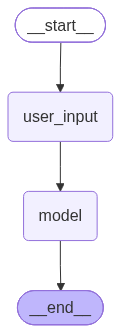

In [6]:
app

In [7]:
result = app.invoke({"messages": ["Hello, write a poem"]})
result

{'messages': ['Hello, write a poem'], 'next_step': 'tools'}